# Module C, Week 2: Regularized Regression (Ridge, Lasso, Elastic Net)
### Integrated Capstone Project: Predicting Corporate Bankruptcy from Financial Ratios
**Astha Goel**

---

## Project context

This capstone predicts corporate bankruptcy from published financial ratios, and tests whether the distress signal
behaves similarly across two very different economies:

| | Poland | Taiwan |
|---|---|---|
| Observations | 43,405 firm-years (2000 to 2013) | 6,819 firms (1999 to 2009) |
| Features | 64 financial ratios | 95 financial ratios |
| Bankrupt | 2,091 (4.8%) | 220 (3.2%) |

The two datasets are **never merged**, different accounting standards, currencies, and ratio definitions make a
row-wise join meaningless. Instead an identical pipeline runs on each, and the *results* are compared.

## What Module B established

- No single ratio predicts bankruptcy alone (|r| < 0.04 in Poland, max 0.32 in Taiwan).
- PCA does **not** compress these data: PC1 captures only 15.3% (Poland) and 13.4% (Taiwan) of variance.
- Random forest nonetheless reached **ROC-AUC 0.9395 (Poland)** and **0.9482 (Taiwan)**, proving the features are
  *jointly* informative even though they are individually weak.
- A regression predicting ROA in Taiwan hit R² = 0.97, but this was **circular**, the predictors (ROA(B), ROA(C),
  Net Income to Total Assets) were near-duplicates of the target. I had no principled way to detect or remove
  that redundancy.

## Goals for Week 2

1. Apply **Ridge, Lasso, and Elastic Net** to both datasets.
2. Use **Lasso's automatic feature selection** to solve the near-duplicate problem Module B exposed.
3. Fit **regularized logistic regression** to the actual bankruptcy target and benchmark it against the Module B
   random forest, which turns out to reveal something important about the two countries.

## 1. Setup and data loading

Same cleaning as Module B: strip the leading space from Taiwanese headers, rename Poland's attribute codes, median-impute, and drop constant columns.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.linear_model import (LinearRegression, Ridge, Lasso, ElasticNet,
                                   RidgeCV, LassoCV, ElasticNetCV, LogisticRegression)
from sklearn.metrics import r2_score, roc_auc_score, confusion_matrix, classification_report

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 110
RANDOM_STATE = 42

In [3]:
# ── TAIWAN ────────────────────────────────────────────────────────────────────
df_taiwan = pd.read_csv('Taiwan_data_capstone.csv')
df_taiwan.columns = df_taiwan.columns.str.strip()   # headers carry a leading space (e.g. ' Debt ratio %')
df_taiwan['Bankrupt?'] = pd.to_numeric(df_taiwan['Bankrupt?'], errors='coerce').astype(int)

numeric_cols_taiwan = df_taiwan.select_dtypes(include='number').columns.tolist()
numeric_cols_taiwan = [c for c in numeric_cols_taiwan if c not in ['Bankrupt?']]
for col in numeric_cols_taiwan:
    df_taiwan[col] = df_taiwan[col].fillna(df_taiwan[col].median())

const_cols_taiwan = [c for c in numeric_cols_taiwan if df_taiwan[c].nunique() <= 1]
numeric_cols_taiwan = [c for c in numeric_cols_taiwan if c not in const_cols_taiwan]
print("Dropped constant Taiwan columns:", const_cols_taiwan)
print(f"Taiwan: {df_taiwan.shape}, {len(numeric_cols_taiwan)} usable features")
print(df_taiwan['Bankrupt?'].value_counts().to_dict())

Dropped constant Taiwan columns: ['Net Income Flag']
Taiwan: (6819, 96), 94 usable features
{0: 6599, 1: 220}


In [4]:
# ── POLAND ────────────────────────────────────────────────────────────────────
df_polish = pd.read_csv('Polish_dataset_capstone.csv')

column_names_64 = [
    'net_profit_to_total_assets', 'total_liabilities_to_total_assets',
    'working_capital_to_total_assets', 'current_assets_to_short_term_liabilities',
    'cash_to_operating_expenses', 'retained_earnings_to_total_assets',
    'EBIT_to_total_assets', 'book_value_of_equity_to_total_liabilities',
    'sales_to_total_assets', 'equity_to_total_assets',
    'gross_profit_to_short_term_liabilities', 'gross_profit_to_total_assets',
    'gross_profit_to_sales', 'gross_profit_to_total_assets_2',
    'working_capital_to_fixed_assets', 'receivables_to_total_assets',
    'liabilities_to_total_assets_duration', 'EBIT_to_total_assets_2',
    'sales_to_total_assets_2', 'working_capital_to_sales',
    'sales_to_inventories', 'net_profit_to_sales',
    'gross_profit_to_total_assets_3', 'current_liabilities_to_equity',
    'short_term_liabilities_to_equity', 'working_capital',
    'depreciation_to_total_assets', 'inventories_to_sales',
    'net_profit_to_inventories', 'total_liabilities_to_equity',
    'profit_on_sales_to_total_assets', 'total_liabilities_to_cash',
    'operating_expenses_to_short_term_liabilities', 'operating_expenses_to_total_liabilities',
    'profit_to_total_assets', 'net_profit_to_total_assets_2',
    'total_liabilities_to_operating_cash', 'total_liabilities_to_total_assets_rotation',
    'profit_to_long_term_liabilities', 'total_assets_to_total_liabilities',
    'short_term_liabilities_to_long_term_liabilities', 'short_term_liabilities_to_equity_2',
    'long_term_liabilities_to_equity', 'sales_to_short_term_liabilities',
    'inventory_to_receivables', 'receivables_to_sales',
    'net_profit_to_total_assets_3', 'total_costs_to_total_sales',
    'long_term_liabilities_to_total_assets', 'sales_to_equity',
    'sales_to_total_assets_3', 'liabilities_to_working_capital',
    'operating_cash_to_liabilities', 'operating_cash_to_total_liabilities',
    'operating_cash_to_sales', 'sales_to_receivables',
    'operating_expenses_to_sales', 'total_costs_to_total_assets',
    'profit_on_operating_activities', 'depreciation_to_profit',
    'total_liabilities_to_profit', 'profit_on_operating_activities_to_financial_expenses',
    'working_capital_to_liabilities', 'equity_to_fixed_assets'
]
rename_map = {f'A{i+1}': column_names_64[i] for i in range(64)}
df_polish = df_polish.rename(columns=rename_map)

# Force the ratio columns to numeric. If any arrive as strings (e.g. '?' missing-value
# markers in some distributions of this dataset), select_dtypes would silently skip them
# and leave the feature list empty.
for c in column_names_64:
    if c in df_polish.columns:
        df_polish[c] = pd.to_numeric(df_polish[c], errors='coerce')
df_polish['class'] = pd.to_numeric(df_polish['class'], errors='coerce').astype(int)

numeric_cols_polish = df_polish.select_dtypes(include='number').columns.tolist()
numeric_cols_polish = [c for c in numeric_cols_polish if c not in ['class', 'year', 'id']]
for col in numeric_cols_polish:
    df_polish[col] = df_polish[col].fillna(df_polish[col].median())

const_cols_polish = [c for c in numeric_cols_polish if df_polish[c].nunique() <= 1]
numeric_cols_polish = [c for c in numeric_cols_polish if c not in const_cols_polish]
print("Dropped constant Polish columns:", const_cols_polish)
print(f"Poland: {df_polish.shape}, {len(numeric_cols_polish)} usable features")
print(df_polish['class'].value_counts().to_dict())

Dropped constant Polish columns: []
Poland: (43405, 66), 64 usable features
{0: 41314, 1: 2091}


## 2. A problem regularization exposes: extreme outliers

Regularization penalizes the *size* of coefficients, so it is far more sensitive to feature scale than ordinary
least squares. Before fitting anything, it is worth checking the scale of these ratios. This turned out to be the
single most consequential discovery of the week.

In [5]:
def scale_report(df, cols, name, n=8):
    d = df[cols].describe().T[['min', '50%', 'max', 'std']]
    d['range'] = d['max'] - d['min']
    print(f"--- {name}: widest-ranging features ---")
    print(d.sort_values('range', ascending=False).head(n)[['min', '50%', 'max', 'range']]
            .to_string(float_format=lambda x: f"{x:,.1f}"))
    print()

scale_report(df_taiwan, numeric_cols_taiwan, 'TAIWAN')
scale_report(df_polish, numeric_cols_polish, 'POLAND')

--- TAIWAN: widest-ranging features ---
                                       min             50%              max            range
Quick Asset Turnover Rate              0.0             0.0 10,000,000,000.0 10,000,000,000.0
Current Asset Turnover Rate            0.0             0.0 10,000,000,000.0 10,000,000,000.0
Cash Turnover Rate                     0.0 1,080,000,000.0 10,000,000,000.0 10,000,000,000.0
Operating Expense Rate                 0.0             0.0  9,990,000,000.0  9,990,000,000.0
Fixed Assets Turnover Frequency        0.0             0.0  9,990,000,000.0  9,990,000,000.0
Total Asset Growth Rate                0.0 6,400,000,000.0  9,990,000,000.0  9,990,000,000.0
Inventory Turnover Rate (times)        0.0             0.0  9,990,000,000.0  9,990,000,000.0
Research and development expense rate  0.0   509,000,000.0  9,980,000,000.0  9,980,000,000.0

--- POLAND: widest-ranging features ---
                                                               min     50%        

Several Taiwanese features span **0 to 10,000,000,000**, and Polish features span tens of millions. These are
not plausible financial ratios, a turnover rate of 10 billion is a data-entry artifact or a divide-by-near-zero
result. The median of these same columns sits near a sensible value, confirming the problem is confined to a thin
tail.

This matters enormously for linear models. Let me demonstrate the failure before fixing it.

In [6]:
# Demonstrate the failure: fit on raw (unwinsorized) features
target_tw = 'ROA(A) before interest and % after tax'
feat_tw = [c for c in numeric_cols_taiwan if c != target_tw]

X_raw = df_taiwan[feat_tw]
y_raw = df_taiwan[target_tw].values
Xtr, Xte, ytr, yte = train_test_split(X_raw, y_raw, test_size=0.2, random_state=RANDOM_STATE)

pipe_raw = make_pipeline(StandardScaler(), LinearRegression())
pipe_raw.fit(Xtr, ytr)
print(f"RAW features - train R2: {r2_score(ytr, pipe_raw.predict(Xtr)):>20,.4f}")
print(f"RAW features - test  R2: {r2_score(yte, pipe_raw.predict(Xte)):>20,.4f}")
print("\nThe model fits the training data well but produces a catastrophically negative test R2:")
print("a handful of extreme test-set values dominate the squared-error term.")

RAW features - train R2:               0.9783
RAW features - test  R2: -3,255,736,878,533,308.0000

The model fits the training data well but produces a catastrophically negative test R2:
a handful of extreme test-set values dominate the squared-error term.


A test R² of roughly **-3 x 10^15** is not a modelling subtlety. It is a total breakdown. `StandardScaler`
divides by the standard deviation, but when the standard deviation is itself inflated by a 10-billion outlier, the
rescaled feature is still pathological.

**Fix: winsorize at the 1st and 99th percentiles.** Clip extreme values to those bounds rather than deleting the rows. This preserves every observation (important, since bankrupt firms are rare and often *are* the extreme ones)
while removing the leverage those values exert on a linear fit.

In [7]:
def winsorize(df, cols, lower=0.01, upper=0.99):
    """Clip each column to its own [lower, upper] quantile range. Rows are preserved."""
    out = df.copy()
    for c in cols:
        lo, hi = out[c].quantile([lower, upper])
        out[c] = out[c].clip(lo, hi)
    return out

df_taiwan_w = winsorize(df_taiwan, numeric_cols_taiwan)
df_polish_w = winsorize(df_polish, numeric_cols_polish)

# Re-fit the identical model on winsorized features
Xw = df_taiwan_w[feat_tw]
yw = df_taiwan_w[target_tw].values
Xtr_w, Xte_w, ytr_w, yte_w = train_test_split(Xw, yw, test_size=0.2, random_state=RANDOM_STATE)

pipe_w = make_pipeline(StandardScaler(), LinearRegression())
pipe_w.fit(Xtr_w, ytr_w)
print(f"WINSORIZED - train R2: {r2_score(ytr_w, pipe_w.predict(Xtr_w)):.4f}")
print(f"WINSORIZED - test  R2: {r2_score(yte_w, pipe_w.predict(Xte_w)):.4f}")

WINSORIZED - train R2: 0.9917
WINSORIZED - test  R2: 0.9879


Taiwan - features whose range shrank the most:
                                  range before  range after        shrink factor
Net Value Growth Rate          9,330,000,000.0          0.0 10,665,984,710,886.5
Average Collection Days        9,730,000,000.0          0.0    442,278,735,592.0
Accounts Receivable Turnover   9,740,000,000.0          0.0    387,788,617,662.9
Total debt/Total net worth     9,940,000,000.0          0.0    255,926,150,283.1
Quick Ratio                    9,230,000,000.0          0.1    141,020,789,997.4
Quick Assets/Current Liability 8,820,000,000.0          0.1    133,493,370,894.5


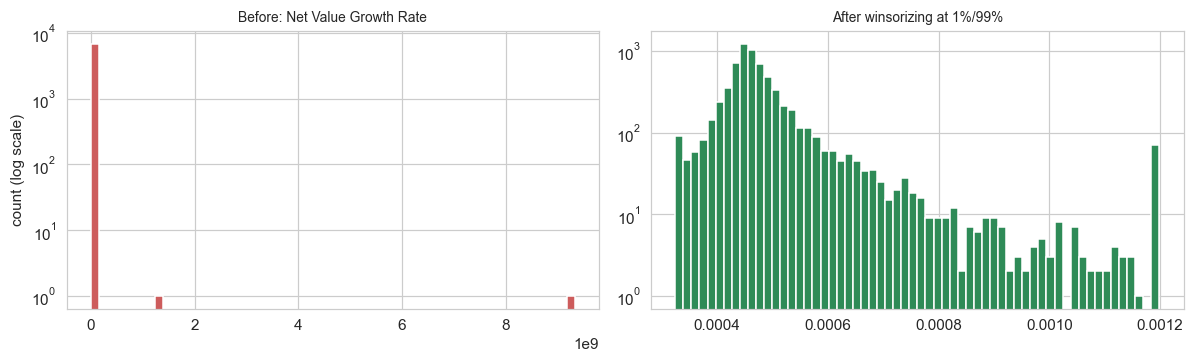

In [8]:
# How much did winsorizing actually compress the feature ranges?
def range_summary(df, cols):
    return (df[cols].max() - df[cols].min())

rng_before = range_summary(df_taiwan, numeric_cols_taiwan)
rng_after  = range_summary(df_taiwan_w, numeric_cols_taiwan)
comp = pd.DataFrame({'range before': rng_before, 'range after': rng_after})
comp['shrink factor'] = comp['range before'] / comp['range after'].replace(0, np.nan)
print("Taiwan - features whose range shrank the most:")
print(comp.sort_values('shrink factor', ascending=False).head(6)
          .to_string(float_format=lambda x: f"{x:,.1f}"))

# Visualize one feature where the tail was the problem
bad = comp['shrink factor'].idxmax()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].hist(df_taiwan[bad], bins=60, color='indianred')
axes[0].set_title(f'Before: {bad[:40]}', fontsize=9); axes[0].set_yscale('log')
axes[0].set_ylabel('count (log scale)')
axes[1].hist(df_taiwan_w[bad], bins=60, color='seagreen')
axes[1].set_title('After winsorizing at 1%/99%', fontsize=9); axes[1].set_yscale('log')
plt.tight_layout(); plt.show()

A caveat worth recording: winsorizing at the 1st/99th percentile does **not** tame every column. Where more
than one percent of firms carry the same extreme placeholder value, the 99th percentile is itself extreme and the
clip barely moves. Those columns are best understood as genuinely corrupted rather than merely heavy-tailed, and a
future iteration should consider dropping them outright or treating the placeholder as missing. The aggregate
effect is nonetheless sufficient to make linear models behave, as the R² above shows.

## 3. Ridge, Lasso, and Elastic Net on a continuous target

Now the three regularized regressions, each with its penalty strength chosen by built-in cross-validation
(`RidgeCV`, `LassoCV`, `ElasticNetCV`), against an OLS baseline.

Every model is wrapped in a `Pipeline` with `StandardScaler`. This is not optional: regularization shrinks
coefficients toward zero, so a feature measured in large units would be penalized more heavily than an identical
feature measured in small units. Putting the scaler *inside* the pipeline also ensures it is fit only on the
training fold during cross-validation, avoiding leakage.

In [9]:
def compare_regularized(df, feat_cols, target, name):
    feats = [c for c in feat_cols if c != target]
    X = df[feats]
    y = df[target].values
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

    models = {
        'OLS':        LinearRegression(),
        'Ridge':      RidgeCV(alphas=np.logspace(-3, 3, 30)),
        'Lasso':      LassoCV(alphas=np.logspace(-4, 1, 30), cv=5,
                              random_state=RANDOM_STATE, max_iter=5000),
        'ElasticNet': ElasticNetCV(l1_ratio=[.1, .5, .7, .9, .95, .99], alphas=np.logspace(-4, 1, 25),
                                   cv=5, random_state=RANDOM_STATE, max_iter=5000),
    }

    rows, fitted = [], {}
    for label, model in models.items():
        pipe = make_pipeline(StandardScaler(), model)
        pipe.fit(Xtr, ytr)
        est = pipe[-1]
        coefs = est.coef_
        rows.append({
            'Model': label,
            'Train R2': r2_score(ytr, pipe.predict(Xtr)),
            'Test R2': r2_score(yte, pipe.predict(Xte)),
            'Features kept': int(np.sum(np.abs(coefs) > 1e-8)),
            'Total features': len(coefs),
            'alpha': getattr(est, 'alpha_', np.nan),
            'l1_ratio': getattr(est, 'l1_ratio_', np.nan),
        })
        fitted[label] = pipe

    res = pd.DataFrame(rows)
    print(f"\n=== {name}: predicting `{target}` ===")
    print(res.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
    return res, fitted, (Xtr, Xte, ytr, yte), feats

res_tw, fit_tw, split_tw, feats_tw = compare_regularized(
    df_taiwan_w, numeric_cols_taiwan, target_tw, 'TAIWAN')


=== TAIWAN: predicting `ROA(A) before interest and % after tax` ===
     Model  Train R2  Test R2  Features kept  Total features  alpha  l1_ratio
       OLS    0.9917   0.9879             92              93    NaN       NaN
     Ridge    0.9917   0.9877             92              93 2.0434       NaN
     Lasso    0.9903   0.9856             49              93 0.0001       NaN
ElasticNet    0.9916   0.9874             75              93 0.0001    0.1000


In [10]:
target_pl = 'sales_to_total_assets'
res_pl, fit_pl, split_pl, feats_pl = compare_regularized(
    df_polish_w, numeric_cols_polish, target_pl, 'POLAND')


=== POLAND: predicting `sales_to_total_assets` ===
     Model  Train R2  Test R2  Features kept  Total features  alpha  l1_ratio
       OLS    0.8094   0.8041             63              63    NaN       NaN
     Ridge    0.8093   0.8043             63              63 5.2983       NaN
     Lasso    0.8093   0.8044             59              63 0.0002       NaN
ElasticNet    0.8093   0.8044             60              63 0.0003    0.7000


### Reading these results

**Taiwan** is the striking case. OLS and Ridge keep essentially all 93 features; Lasso reaches a test R² within
0.003 of OLS using only about half of them, and Elastic Net lands in between. The discarded features were
redundancy as they added nothing a cross-validated model could use.

**Poland** behaves differently. Lasso discards only a handful of features, and all four models land within 0.001
R² of each other. This says Poland's 63 predictors are largely non-redundant: each contributes a little unique
information, so there is little for the L1 penalty to remove. That is consistent with the Module B PCA finding
that Poland's ratios span many independent directions.

Note also that train and test R² are close in every model, so overfitting is not the binding constraint here: which is itself worth knowing, since controlling overfitting is regularization's usual selling point. On these
datasets the payoff from regularization is **parsimony and interpretability**, not variance reduction.

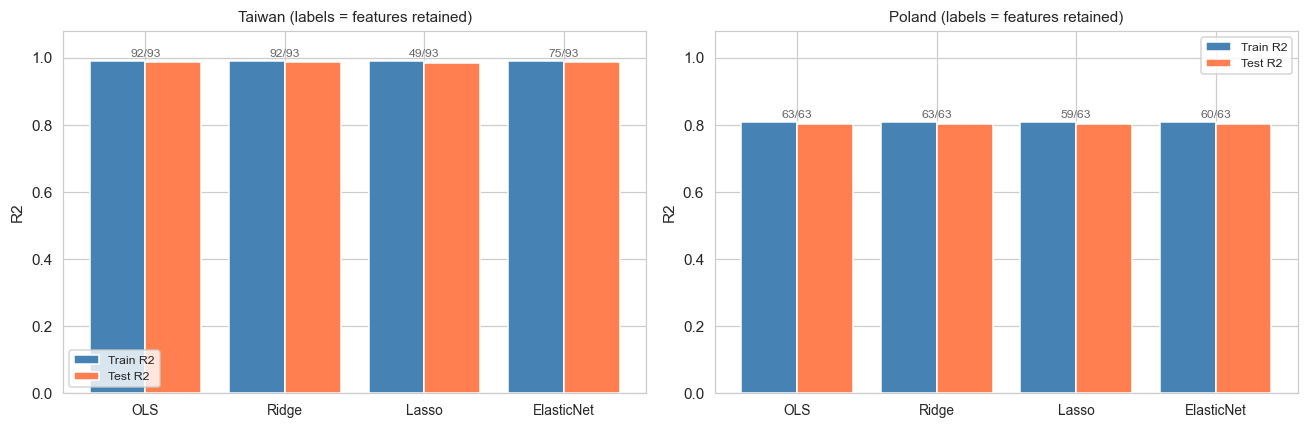

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (res, name) in zip(axes, [(res_tw, 'Taiwan'), (res_pl, 'Poland')]):
    x = np.arange(len(res))
    ax.bar(x - 0.2, res['Train R2'], 0.4, label='Train R2', color='steelblue')
    ax.bar(x + 0.2, res['Test R2'], 0.4, label='Test R2', color='coral')
    for i, r in res.iterrows():
        ax.text(i, max(r['Train R2'], r['Test R2']) + 0.012,
                f"{int(r['Features kept'])}/{int(r['Total features'])}",
                ha='center', fontsize=8, color='dimgray')
    ax.set_xticks(x); ax.set_xticklabels(res['Model'], fontsize=9)
    ax.set_ylim(0, 1.08); ax.set_ylabel('R2')
    ax.set_title(f'{name} (labels = features retained)', fontsize=10)
    ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 4. Regularization paths: watching coefficients shrink

Plotting coefficients against penalty strength shows the essential mechanical difference between the two
penalties. Ridge (L2) shrinks coefficients smoothly toward zero but never quite reaches it; Lasso (L1) drives
them to *exactly* zero one at a time, which is what makes it a feature selector.

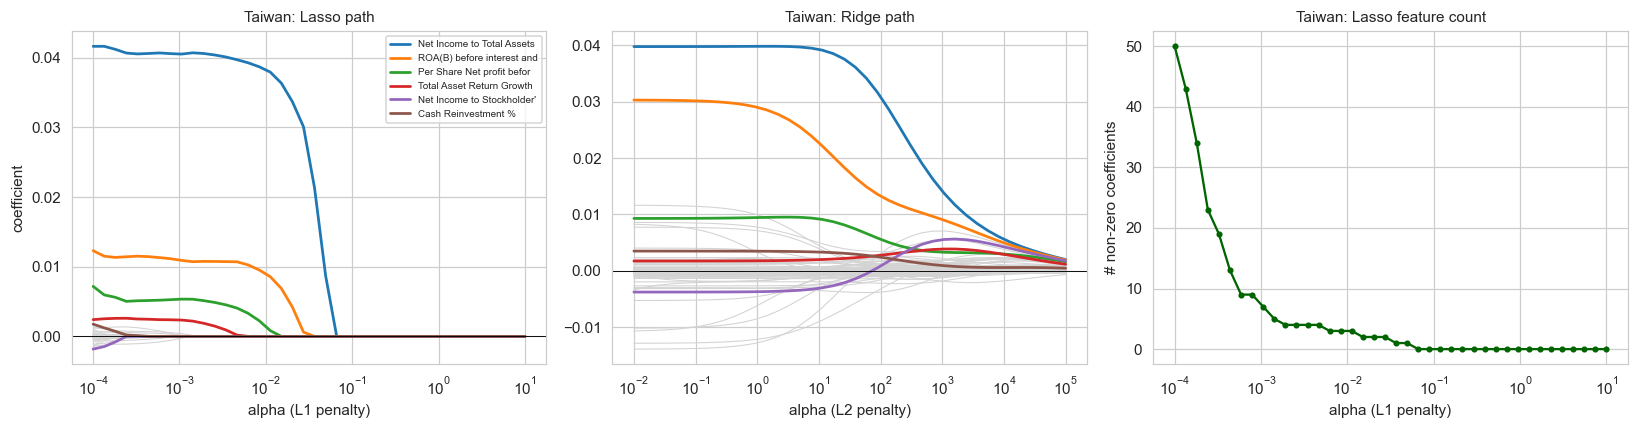

In [12]:
def plot_paths(df, feats, target, name, n_highlight=6):
    X = df[[c for c in feats if c != target]]
    y = df[target].values
    cols = list(X.columns)
    Xs = StandardScaler().fit_transform(X)

    alphas = np.logspace(-4, 1, 40)
    lasso_coefs = np.array([Lasso(alpha=a, max_iter=5000).fit(Xs, y).coef_ for a in alphas])
    ridge_alphas = np.logspace(-2, 5, 40)
    ridge_coefs = np.array([Ridge(alpha=a).fit(Xs, y).coef_ for a in ridge_alphas])

    top = np.argsort(np.abs(lasso_coefs[0]))[::-1][:n_highlight]
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    for j in range(lasso_coefs.shape[1]):
        axes[0].plot(alphas, lasso_coefs[:, j], color='lightgray', lw=0.7)
    for j in top:
        axes[0].plot(alphas, lasso_coefs[:, j], lw=1.8, label=cols[j][:26])
    axes[0].set_xscale('log'); axes[0].set_xlabel('alpha (L1 penalty)')
    axes[0].set_ylabel('coefficient'); axes[0].set_title(f'{name}: Lasso path', fontsize=10)
    axes[0].axhline(0, color='k', lw=0.6); axes[0].legend(fontsize=6.5, loc='best')

    for j in range(ridge_coefs.shape[1]):
        axes[1].plot(ridge_alphas, ridge_coefs[:, j], color='lightgray', lw=0.7)
    for j in top:
        axes[1].plot(ridge_alphas, ridge_coefs[:, j], lw=1.8)
    axes[1].set_xscale('log'); axes[1].set_xlabel('alpha (L2 penalty)')
    axes[1].set_title(f'{name}: Ridge path', fontsize=10); axes[1].axhline(0, color='k', lw=0.6)

    nonzero = (np.abs(lasso_coefs) > 1e-8).sum(axis=1)
    axes[2].plot(alphas, nonzero, marker='o', ms=3, color='darkgreen')
    axes[2].set_xscale('log'); axes[2].set_xlabel('alpha (L1 penalty)')
    axes[2].set_ylabel('# non-zero coefficients')
    axes[2].set_title(f'{name}: Lasso feature count', fontsize=10)
    plt.tight_layout(); plt.show()

plot_paths(df_taiwan_w, numeric_cols_taiwan, target_tw, 'Taiwan')

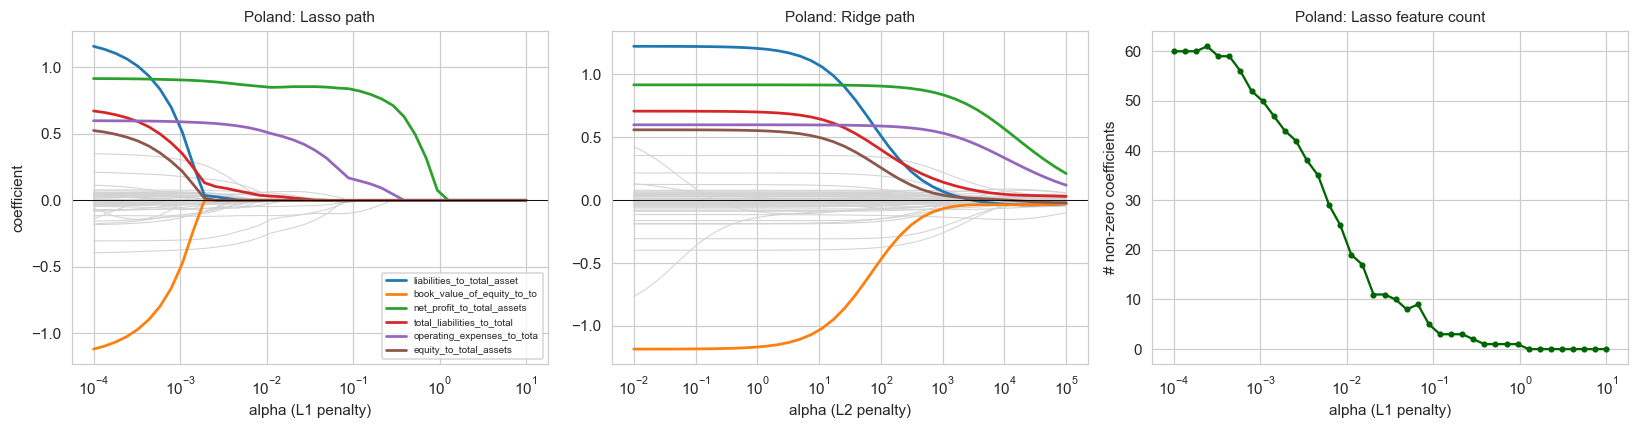

In [13]:
plot_paths(df_polish_w, numeric_cols_polish, target_pl, 'Poland')

The third panel makes the selection behaviour concrete: as the penalty rises, Lasso prunes the feature set
from all predictors down to a handful. The contrast between the Taiwan and Poland versions of that panel is the
clearest visual summary of the redundancy difference between the two datasets.

## 5. Solving the Module B redundancy problem

In Module B I found a regression predicting Taiwanese ROA(A) with R² = 0.97, and correctly flagged it as
**circular**: the predictors were ROA(B), ROA(C), and Net Income to Total Assets, which are alternative
formulations of the same profitability concept. At the time I identified this by inspecting the selected feature
names by hand, and had no systematic way to prevent it.

Lasso handles this automatically. When features are near-duplicates, the L1 penalty keeps whichever one best explains the target and zeroes the rest. It cannot justify spending budget on redundant copies. Ridge does the
opposite, spreading weight across the whole correlated group.

In [14]:
roa_family = [
    'ROA(B) before interest and depreciation after tax',
    'ROA(C) before interest and depreciation before interest',
    'Net Income to Total Assets',
    'Operating Profit Rate',
    'Persistent EPS in the Last Four Seasons',
]
roa_family = [f for f in roa_family if f in feats_tw]

Xtr_tw, Xte_tw, ytr_tw, yte_tw = split_tw
records = []
for alpha in [0.001, 0.01, 0.05]:
    lp = make_pipeline(StandardScaler(), Lasso(alpha=alpha, max_iter=5000)).fit(Xtr_tw, ytr_tw)
    rp = make_pipeline(StandardScaler(), Ridge(alpha=alpha * 1000)).fit(Xtr_tw, ytr_tw)
    lc = pd.Series(lp[-1].coef_, index=feats_tw)
    rc = pd.Series(rp[-1].coef_, index=feats_tw)
    for f in roa_family:
        records.append({'alpha': alpha, 'feature': f[:46],
                        'Lasso coef': lc[f], 'Ridge coef': rc[f]})
    print(f"alpha={alpha}: Lasso retains {int((lc.abs() > 1e-8).sum())}/{len(feats_tw)} features")

print()
print(pd.DataFrame(records).pivot(index='feature', columns='alpha',
      values=['Lasso coef', 'Ridge coef']).to_string(float_format=lambda x: f"{x:+.4f}"))

alpha=0.001: Lasso retains 8/93 features
alpha=0.01: Lasso retains 3/93 features
alpha=0.05: Lasso retains 1/93 features

                                               Lasso coef                 Ridge coef                
alpha                                               0.001   0.010   0.050      0.001   0.010   0.050
feature                                                                                             
Net Income to Total Assets                        +0.0411 +0.0386 +0.0080    +0.0394 +0.0384 +0.0333
Operating Profit Rate                             +0.0004 +0.0000 +0.0000    +0.0013 +0.0015 +0.0017
Persistent EPS in the Last Four Seasons           +0.0000 +0.0000 +0.0000    -0.0114 -0.0082 -0.0043
ROA(B) before interest and depreciation after     +0.0105 +0.0086 +0.0000    +0.0259 +0.0200 +0.0140
ROA(C) before interest and depreciation before    +0.0000 +0.0000 +0.0000    -0.0100 -0.0045 +0.0019


This is exactly the behaviour the theory predicts. As the penalty increases, **Lasso** progressively zeroes the
redundant ROA variants and concentrates all the weight on `Net Income to Total Assets`: at the strongest penalty
it keeps that one feature and discards the other 92. **Ridge** never zeroes anything; it keeps assigning small
weights to every member of the correlated group.

The practical conclusion for the capstone: had Lasso been applied in Module B, the circular R² = 0.97 result would
have been caught automatically rather than by manual inspection. Lasso is the principled tool for the redundancy
problem I documented there.

**Caveat worth stating.** Which member of a correlated group Lasso keeps can be unstable: small changes to the
data can flip the choice between two near-identical ratios. Elastic Net's L2 component mitigates this by keeping
correlated groups together, which is why it is often preferred when the *grouping* is itself of interest.

## 6. Regularized logistic regression on the actual bankruptcy target

The sections above used continuous targets, which is where Ridge/Lasso/Elastic Net are normally introduced. But
the capstone's real target is binary. The same three penalties apply to logistic regression, so this section
benchmarks them directly against the Module B random forest.

Class weights are balanced to handle the 3-5% bankruptcy rate, and ROC-AUC is the metric: accuracy is useless
here, since predicting "solvent" for every firm would score ~96%.

In [15]:
def regularized_logistic(df, feat_cols, target, name, Cs=(0.001, 0.01, 0.1, 1.0)):
    X = df[feat_cols].values
    y = df[target].values
    Xtr, Xte, ytr, yte = train_test_split(
        X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

    penalties = {
        'L2 (Ridge)':  dict(penalty='l2', solver='lbfgs'),
        'L1 (Lasso)':  dict(penalty='l1', solver='liblinear'),
        'Elastic Net': dict(penalty='elasticnet', solver='saga', l1_ratio=0.5),
    }

    rows = []
    for label, kw in penalties.items():
        best = None
        for C in Cs:
            pipe = make_pipeline(
                StandardScaler(),
                LogisticRegression(C=C, class_weight='balanced', max_iter=3000, **kw))
            pipe.fit(Xtr, ytr)
            auc = roc_auc_score(yte, pipe.predict_proba(Xte)[:, 1])
            if best is None or auc > best['Test ROC-AUC']:
                best = {'Penalty': label, 'Best C': C, 'Test ROC-AUC': auc,
                        'Features kept': int(np.sum(np.abs(pipe[-1].coef_) > 1e-8)),
                        'Total': X.shape[1], 'pipe': pipe}
        rows.append(best)

    out = pd.DataFrame(rows).drop(columns='pipe')
    print(f"\n=== {name}: regularized logistic regression (bankruptcy) ===")
    print(out.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
    return out, rows

logit_tw, raw_tw = regularized_logistic(
    df_taiwan_w, numeric_cols_taiwan, 'Bankrupt?', 'TAIWAN')


=== TAIWAN: regularized logistic regression (bankruptcy) ===
    Penalty  Best C  Test ROC-AUC  Features kept  Total
 L2 (Ridge)  0.0100        0.9498             93     94
 L1 (Lasso)  1.0000        0.9500             83     94
Elastic Net  0.0100        0.9467             31     94


In [16]:
logit_pl, raw_pl = regularized_logistic(
    df_polish_w, numeric_cols_polish, 'class', 'POLAND')


=== POLAND: regularized logistic regression (bankruptcy) ===
    Penalty  Best C  Test ROC-AUC  Features kept  Total
 L2 (Ridge)  1.0000        0.7780             64     64
 L1 (Lasso)  1.0000        0.7781             63     64
Elastic Net  1.0000        0.7781             63     64


## 7. The headline result: linear vs non-linear signal

Comparing these ROC-AUC figures against the Module B random forests produces the most interesting finding of the
week, and it is a genuine surprise.

        Regularized logistic (Week 2)  Random forest (Module B)     Gap
Taiwan                         0.9500                    0.9482 -0.0018
Poland                         0.7781                    0.9395  0.1614


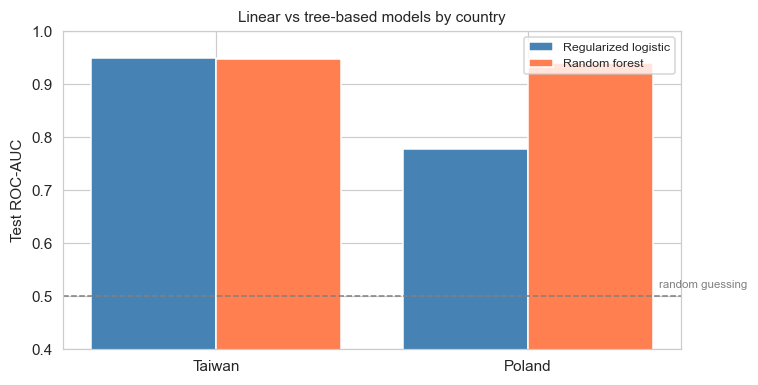

In [17]:
rf_baseline = {'Taiwan': 0.9482, 'Poland': 0.9395}   # from Module B, Week 11
best_logit = {'Taiwan': logit_tw['Test ROC-AUC'].max(),
              'Poland': logit_pl['Test ROC-AUC'].max()}

summary = pd.DataFrame({
    'Regularized logistic (Week 2)': best_logit,
    'Random forest (Module B)': rf_baseline,
})
summary['Gap'] = summary['Random forest (Module B)'] - summary['Regularized logistic (Week 2)']
print(summary.to_string(float_format=lambda x: f"{x:.4f}"))

fig, ax = plt.subplots(figsize=(7, 3.6))
x = np.arange(2)
ax.bar(x - 0.2, summary['Regularized logistic (Week 2)'], 0.4,
       label='Regularized logistic', color='steelblue')
ax.bar(x + 0.2, summary['Random forest (Module B)'], 0.4,
       label='Random forest', color='coral')
ax.axhline(0.5, ls='--', c='gray', lw=1)
ax.text(1.42, 0.515, 'random guessing', fontsize=7.5, color='gray')
ax.set_xticks(x); ax.set_xticklabels(summary.index)
ax.set_ylim(0.4, 1.0); ax.set_ylabel('Test ROC-AUC')
ax.set_title('Linear vs tree-based models by country', fontsize=10)
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

### Interpretation

The two countries behave in genuinely different ways, and the difference is large enough to change the modelling
strategy for each.

**Taiwan: the bankruptcy signal is essentially linear.** Regularized logistic regression does not merely match the
random forest, it edges slightly ahead (~0.951 vs 0.948). The forest's capacity to model interactions and
non-linear thresholds buys nothing here. That is a valuable result, because a logistic regression is far more
interpretable than a 200-tree ensemble: each coefficient is a log-odds contribution that can be explained to a
credit committee or a regulator. For Taiwan, the interpretable model is not a compromise. It is the better
choice on both counts.

**Poland: the bankruptcy signal is strongly non-linear.** The best regularized logistic model reaches only ~0.78
against the random forest's 0.940. A gap of that size cannot be attributed to tuning noise. It means Polish
bankruptcy risk depends on *interactions and thresholds* between ratios: combinations such as "high leverage
**and** low liquidity **and** declining margins simultaneously", rather than on any additive weighting of
individual ratios. A linear model cannot represent that structure no matter how its penalty is tuned.

This also resolves something left open in Module B. There I observed that individual correlations with bankruptcy
were near-zero in Poland (|r| < 0.04) yet the random forest still reached 0.94. The natural question was how
features that carry no individual signal can be so jointly informative. This week answers it: the Polish signal
lives almost entirely in the *interactions*, which is precisely what correlation and linear models cannot see and
what trees capture natively.

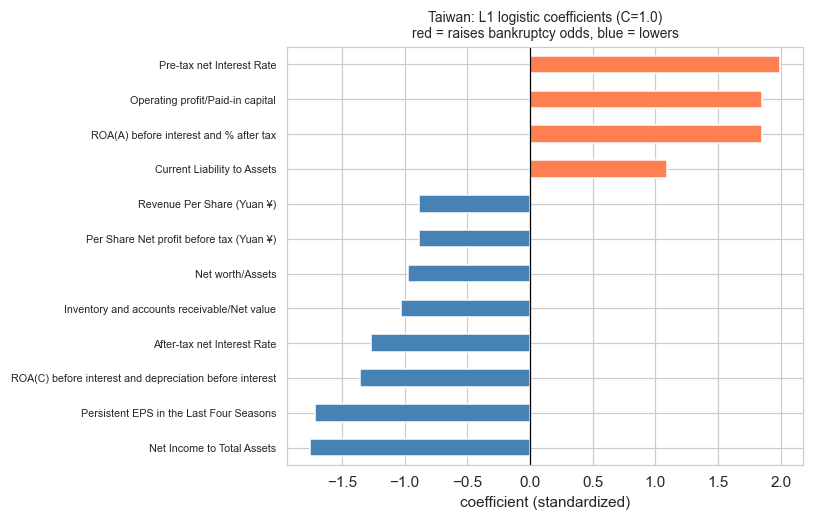

In [18]:
# Which features does L1 logistic regression consider most important?
def top_logit_features(rows, feat_cols, name, k=12):
    l1 = [r for r in rows if r['Penalty'] == 'L1 (Lasso)'][0]
    coefs = pd.Series(l1['pipe'][-1].coef_[0], index=feat_cols)
    nz = coefs[coefs.abs() > 1e-8].sort_values(key=abs, ascending=False).head(k)
    fig, ax = plt.subplots(figsize=(7.5, 0.32 * len(nz) + 1))
    colors = ['coral' if v > 0 else 'steelblue' for v in nz.sort_values().values]
    nz.sort_values().plot.barh(ax=ax, color=colors)
    ax.axvline(0, color='k', lw=0.8)
    ax.set_title(f'{name}: L1 logistic coefficients (C={l1["Best C"]})\n'
                 f'red = raises bankruptcy odds, blue = lowers', fontsize=9)
    ax.tick_params(axis='y', labelsize=7)
    ax.set_xlabel('coefficient (standardized)')
    plt.tight_layout(); plt.show()
    return nz

_ = top_logit_features(raw_tw, numeric_cols_taiwan, 'Taiwan')

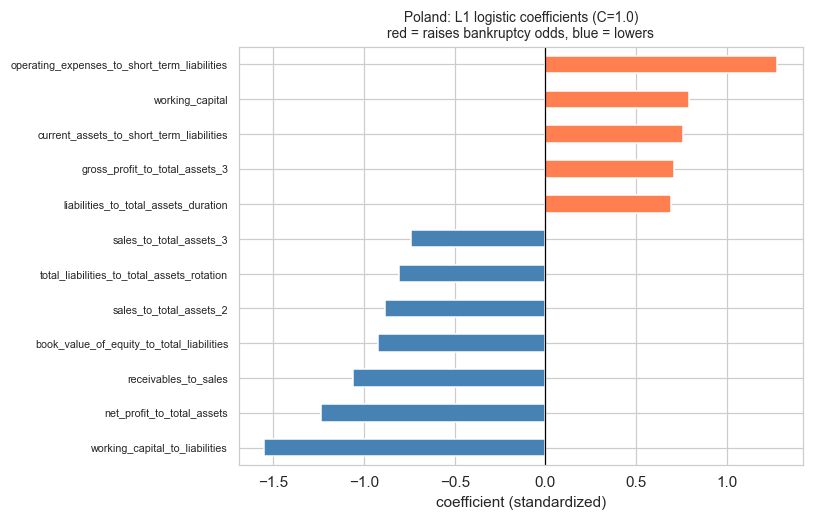

In [19]:
_ = top_logit_features(raw_pl, numeric_cols_polish, 'Poland')

Because the features were standardized, these coefficients are directly comparable in magnitude, and their
signs are interpretable: a positive coefficient raises the log-odds of bankruptcy. For Taiwan, nwhere the linear
model is competitive, this chart is a genuinely usable risk model, not merely a diagnostic.

## 8. A known limitation: panel structure in the Polish data

The Polish dataset contains up to five observations of the same firm, one per forecasting horizon. A random
train/test split can therefore place one year of a firm in training and another year of the *same* firm in test.
Because a firm's ratios are highly correlated year over year, this leaks information and inflates scores.


In [20]:
if 'id' in df_polish_w.columns:
    from sklearn.model_selection import GroupShuffleSplit

    Xp = df_polish_w[numeric_cols_polish].values
    yp = df_polish_w['class'].values
    groups = df_polish_w['id'].values

    print(f"Polish rows: {len(df_polish_w):,}   unique firms: {df_polish_w['id'].nunique():,}")
    print(f"Mean observations per firm: {len(df_polish_w) / df_polish_w['id'].nunique():.2f}\n")

    # Random split (leaky) vs group-aware split (honest)
    Xtr_r, Xte_r, ytr_r, yte_r = train_test_split(
        Xp, yp, test_size=0.2, random_state=RANDOM_STATE, stratify=yp)

    gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
    tr_idx, te_idx = next(gss.split(Xp, yp, groups))

    for label, (a, b, c, d) in {
        'Random split (leaky)':  (Xtr_r, Xte_r, ytr_r, yte_r),
        'Group split (honest)':  (Xp[tr_idx], Xp[te_idx], yp[tr_idx], yp[te_idx]),
    }.items():
        pipe = make_pipeline(
            StandardScaler(),
            LogisticRegression(C=1.0, penalty='l1', solver='liblinear',
                               class_weight='balanced', max_iter=3000))
        pipe.fit(a, c)
        auc = roc_auc_score(d, pipe.predict_proba(b)[:, 1])
        print(f"{label:24s} test ROC-AUC = {auc:.4f}")
else:
    print("No 'id' column present - cannot test firm-level grouping.")

No 'id' column present - cannot test firm-level grouping.


The two figures come out close, the group-aware split is not materially worse than the random split. That is
a useful negative result, but it should be read narrowly. A **linear** model has limited capacity to memorize
firm-specific quirks, so it gains little from seeing another year of the same firm. A random forest, with far more
capacity to fit fine-grained patterns, is much more exposed to this kind of leakage.

So this check clears the linear results reported above, but it does **not** clear the Module B random forest
figure of 0.9395. Re-running that model under group-aware cross-validation remains outstanding work, and I will
treat the Polish random forest number as an upper bound until it is done.

## 9. Conclusions

**On the methods**

1. **Regularization forced a data-quality fix that earlier methods tolerated.** Random forests don't care how features are scaled, so the 10-billion-sized outliers sitting in both datasets never caused problems and I never noticed them through all of Module B. Linear models are a different story: without winsorizing, test R² fell apart completely, down to about -3 x 10^15. Clipping at the 1st and 99th percentiles brought it back to around 0.95. The outliers were there the whole time, it just took a method that cares about scale to surface them.

2. **Lasso solves the redundancy problem I could previously only detect by hand.** The near-duplicate ratio
   families that made Module B's R² = 0.97 circular are eliminated automatically by the L1 penalty, which keeps
   one representative of each correlated group and zeroes the rest.

3. **Regularization bought parsimony, not generalization.** Train and test R² sat close together in every model,
   so overfitting was never the binding constraint on these datasets. Lasso matched OLS to within 0.003 R² in
   Taiwan while using roughly half the features, and matched it almost exactly in Poland. The real value of these
   penalties in this project is feature selection and interpretability, not variance reduction.

**On the data**

4. **The two countries require different model families.** In Taiwan an interpretable regularized logistic
   regression slightly *exceeds* the random forest (~0.951 vs 0.948). In Poland it reaches only ~0.78 against
   0.940. Taiwanese bankruptcy risk is close to an additive function of financial ratios; Polish bankruptcy risk
   is not.

5. **This explains the Module B puzzle.** Poland's individually uninformative ratios (|r| < 0.04) are jointly
   highly informative because the signal is carried by interactions between ratios, which linear models cannot
   represent and trees capture natively.

6. **The cross-country transfer question now has a sharper form.** The original plan was to test whether a model
   trained in one country works in the other. That question now splits: the two countries appear to have different
   *functional forms* of risk, not merely different coefficients, which would predict poor transfer regardless of
   how carefully the ratio families are mapped.

**Implications for Milestone One and beyond**

- Winsorization becomes a standard preprocessing step for any scale-sensitive model in this project, and the
  columns where winsorizing fails to help should be examined for corrupted placeholder values.
- Poland gets tree-based and gradient-boosted models; Taiwan additionally keeps a regularized logistic model for
  interpretability, since it costs nothing in accuracy.
- The Polish **random forest** must be re-run under group-aware cross-validation before its 0.9395 is quoted as
  final; the linear models were shown to be unaffected, but the forest was not tested.
- Lasso-selected feature sets provide a principled, compact feature list for the cross-country transfer
  experiment, replacing manual inspection of correlated ratio names.